# 01 · The Classical U

**Claim:** the textbook picture is real. Below the interpolation threshold, test error falls, bottoms out at a sweet spot, and rises again, because bias falls while variance rises.

This notebook reproduces that picture first, so nothing later is a strawman. The rest of the series shows it is only half the curve.

*Double Descent 101 · notebook 1 of 6 · next: [02 · The interpolation peak](02_the_interpolation_peak.ipynb)*

## Setup: two tracks, one truth each

Double descent is about test error against the **truth**, so every dataset here has a known true function $f$ and Gaussian label noise $y = f(x) + \sigma\,\varepsilon$.

| Track | Inputs | True function | Model | Parameters $p$ | Training points $n$ |
|---|---|---|---|---|---|
| Polynomial | $x \sim U[-1, 1]$ | $\sin(\pi x) + 0.5\cos(2\pi x)$ | Legendre polynomial, degree $p-1$ | degree + 1 | 15 |
| Random features | $x \sim N(0, I_{20})$ | $\tanh(2\langle\beta, x\rangle)$ | $p$ frozen random ReLU features + linear read-out | width | 100 |

Every model is fitted by **minimum-norm least squares** (the pseudo-inverse). Below the threshold that is ordinary least squares. Test error is the MSE against the noiseless $f$ on 2,000 fixed test inputs. Curves show the **median over many training draws**, with the interquartile range as a band. The headline noise level is $\sigma = 0.3$ (the signal variance is about 0.6).

In [1]:
import numpy as np
import pandas as pd

from src.config import get_settings
from src.evaluation import aggregate, example_fits, factory_for, run_capacity_experiment, summarize_curve, task_for
from src.evaluation.comparison import MODEL_LABELS
from src.reporting import publish_figure, save_json
from src.theory.decomposition import bias_variance
from src.visualisation import (
    BIAS_COLOR, INK, MODEL_COLORS, TRAIN_COLOR, VARIANCE_COLOR,
    annotate_point, format_error, new_figure, plot_curve, plot_decomposition, plot_fit,
)

settings = get_settings()
SIGMA = settings.headline_noise
N_POLY = settings.polynomial.n_train
N_RF = settings.random_features.n_train
print(f"headline noise σ = {SIGMA}; polynomial n = {N_POLY}; random features n = {N_RF}")

headline noise σ = 0.3; polynomial n = 15; random features n = 100


In [2]:
# Capacity sweeps for both tracks (all noise levels share the same draws).
poly = run_capacity_experiment("polynomial", settings)
rf = run_capacity_experiment("random_features", settings)

def curves(df, n):
    test = aggregate(df[df["noise"] == SIGMA])
    train = aggregate(df[df["noise"] == SIGMA], value="train_mse")
    return test, train, summarize_curve(test, n)

poly_test, poly_train, poly_sum = curves(poly, N_POLY)
rf_test, rf_train, rf_sum = curves(rf, N_RF)
pd.DataFrame({"polynomial": poly_sum.to_dict(), "random features": rf_sum.to_dict()}).loc[
    ["classical_min_params", "classical_min_error", "peak_params", "peak_error"]
]

,polynomial,random features
classical_min_params,5,32
classical_min_error,0.124077,0.416722
peak_params,15,100
peak_error,3210621083.103967,71.448123


## The U, measured

Only the underparameterized side ($p < n$) for now. Training error (grey, dashed) can only fall as the model grows. Test error falls while extra capacity captures real structure, then rises once the model starts chasing the noise.

{'png': '/workspaces/double_descent_101/outputs/figures/01_classical_u.png',
 'json': '/workspaces/double_descent_101/outputs/data/01_classical_u.json'}

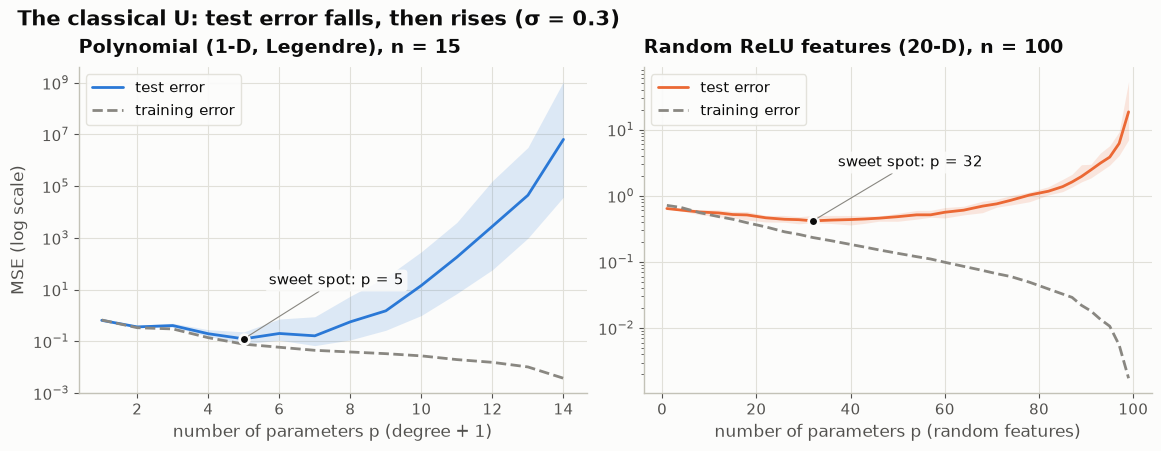

In [3]:
fig, axes = new_figure(ncols=2, width=11.5, height=4.4)
panels = [
    (axes[0], poly_test, poly_train, poly_sum, N_POLY, "polynomial", "degree + 1"),
    (axes[1], rf_test, rf_train, rf_sum, N_RF, "random_features", "random features"),
]
fig_data = {}
for ax, test, train, summ, n, model, unit in panels:
    t = test[test["n_params"] < n]
    tr = train[train["n_params"] < n]
    plot_curve(ax, t, MODEL_COLORS[model], "test error")
    plot_curve(ax, tr, TRAIN_COLOR, "training error", band=False, ls="--")
    annotate_point(ax, summ.classical_min_params, summ.classical_min_error,
                   f"sweet spot: p = {summ.classical_min_params}", dx=18, dy=42)
    ax.set_yscale("log")
    ax.set_xlabel(f"number of parameters p ({unit})")
    ax.set_title(f"{MODEL_LABELS[model]}, n = {n}")
    ax.legend(loc="upper left")
    fig_data[model] = {
        "n_train": n,
        "n_params": t["n_params"].tolist(),
        "test_median": t["median"].tolist(), "test_q25": t["q25"].tolist(), "test_q75": t["q75"].tolist(),
        "train_median": tr["median"].tolist(),
        "sweet_spot": {"n_params": summ.classical_min_params, "test_mse": summ.classical_min_error},
    }
axes[0].set_ylabel("MSE (log scale)")
fig.suptitle(f"The classical U: test error falls, then rises (σ = {SIGMA})", x=0.01, ha="left")
publish_figure(
    fig, "01_classical_u", "The classical U",
    "Median test error (vs the noiseless truth) and training error against model size, "
    f"underparameterized side only, noise σ = {SIGMA}. Bands: interquartile range over training draws.",
    {"noise": SIGMA, **fig_data},
)

## Why it is a U: bias down, variance up

The textbook explanation, estimated directly. Refit on many independent training sets and split the expected test error at each size:

$$\underbrace{\mathbb{E}\,(\hat f(x) - f(x))^2}_{\text{expected test MSE}} = \underbrace{(\mathbb{E}\hat f(x) - f(x))^2}_{\text{bias}^2} + \underbrace{\operatorname{Var}\hat f(x)}_{\text{variance}}$$

This uses the random-feature track. Polynomial errors are too heavy-tailed for averages: one rare draw with two almost-identical inputs can dominate a mean of thousands.

,n_params,n_train,noise,bias2,variance,expected_mse,noise_var
0,1,100,0.3,0.6200,0.0177,0.6377,0.09
1,4,100,0.3,0.5293,0.0798,0.6091,0.09
2,8,100,0.3,0.4206,0.1507,0.5713,0.09
3,12,100,0.3,0.3338,0.2024,0.5362,0.09
4,15,100,0.3,0.2847,0.2260,0.5107,0.09
5,18,100,0.3,0.2415,0.2468,0.4883,0.09
6,22,100,0.3,0.1978,0.2670,0.4647,0.09
7,26,100,0.3,0.1698,0.2819,0.4516,0.09
8,29,100,0.3,0.1535,0.2876,0.4411,0.09
9,32,100,0.3,0.1411,0.2922,0.4332,0.09


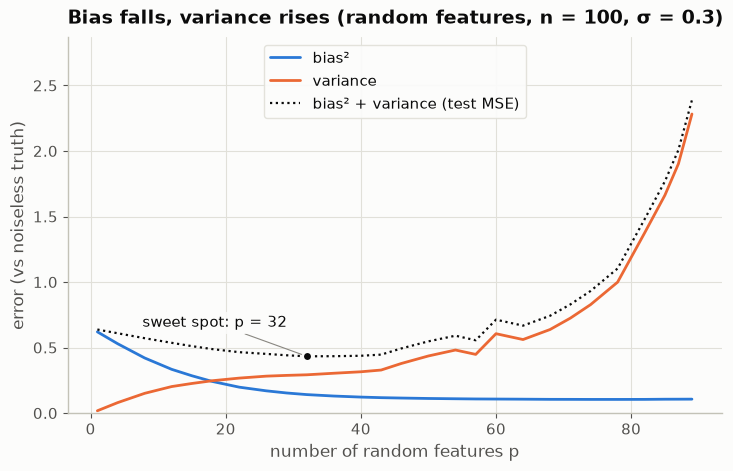

In [4]:
rf_cfg = settings.random_features
under_grid = [p for p in rf_test["n_params"] if p < 0.9 * N_RF]
dec_under = bias_variance(
    factory_for("random_features", settings), task_for("random_features", settings),
    n_train=N_RF, noise=SIGMA, n_params_grid=under_grid,
    n_draws=rf_cfg.decomposition_draws, seed=settings.seed,
)
assert np.allclose(dec_under["bias2"] + dec_under["variance"], dec_under["expected_mse"])
best = dec_under.loc[dec_under["expected_mse"].idxmin()]

fig, (ax,) = new_figure(width=7.2, height=4.6)
plot_decomposition(ax, dec_under, N_RF)
annotate_point(ax, best["n_params"], best["expected_mse"], f"sweet spot: p = {int(best['n_params'])}", dx=-14, dy=24, ha="right")
ax.set_xlabel("number of random features p")
ax.set_ylabel("error (vs noiseless truth)")
ax.set_ylim(0, 1.2 * dec_under["expected_mse"].max())
ax.set_title(f"Bias falls, variance rises (random features, n = {N_RF}, σ = {SIGMA})")
ax.legend(loc="upper center")
publish_figure(
    fig, "01_bias_variance", "Bias falls, variance rises",
    f"Empirical bias-variance decomposition over {rf_cfg.decomposition_draws} independent training draws "
    f"(fresh inputs, noise and random features), random-feature track, underparameterized side, σ = {SIGMA}.",
    {"noise": SIGMA, "n_train": N_RF, "n_draws": rf_cfg.decomposition_draws, "decomposition": dec_under},
)
dec_under.round(4)

## What the U looks like as curves

One training draw of the polynomial track, fitted at three sizes: too simple, the sweet spot, and too complex (but still below the threshold).

{'png': '/workspaces/double_descent_101/outputs/figures/01_fits_underfit_to_overfit.png',
 'json': '/workspaces/double_descent_101/outputs/data/01_fits_underfit_to_overfit.json'}

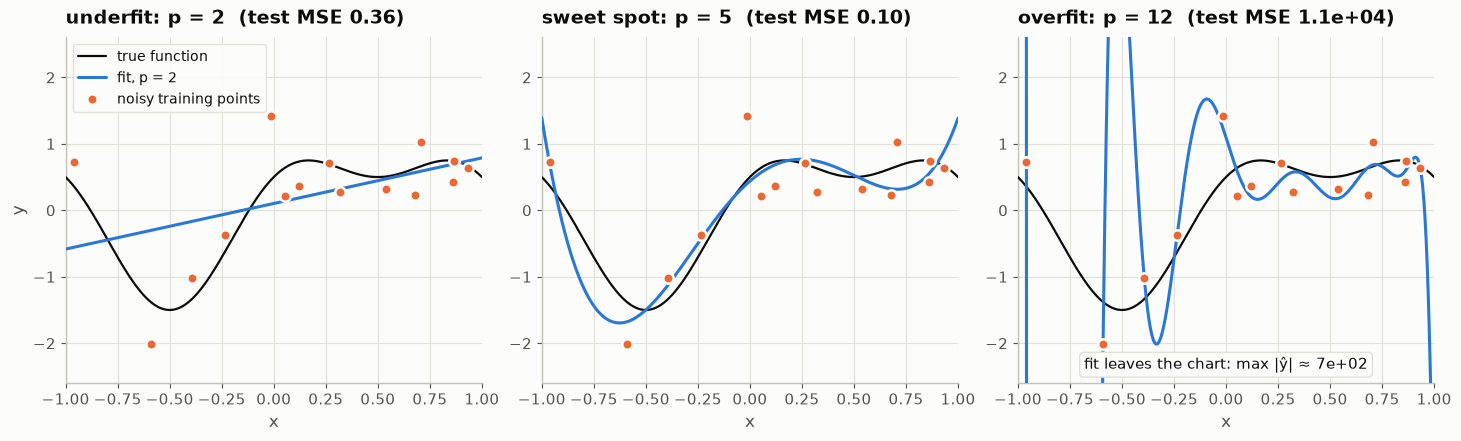

In [5]:
sizes = [2, poly_sum.classical_min_params, N_POLY - 3]
ex = example_fits(settings, sizes, noise=SIGMA)
names = ["underfit", "sweet spot", "overfit"]
fig, axes = new_figure(ncols=3, width=14.5, height=4.3)
for ax, p, name in zip(axes, sizes, names):
    plot_fit(ax, ex.x_grid, ex.f_grid, ex.x_train, ex.y_train, ex.predictions[p], label=f"fit, p = {p}")
    ax.set_title(f"{name}: p = {p}  (test MSE {format_error(ex.test_mse[p])})")
axes[0].legend(loc="upper left", fontsize=10)
for ax in axes[1:]:
    ax.set_ylabel("")
publish_figure(
    fig, "01_fits_underfit_to_overfit", "Underfit, sweet spot, overfit",
    f"One training draw of {N_POLY} noisy points (σ = {SIGMA}) from the true function (black), fitted with "
    f"Legendre polynomials of {sizes[0]}, {sizes[1]} and {sizes[2]} parameters.",
    {"noise": SIGMA, "x_train": ex.x_train, "y_train": ex.y_train, "x_grid": ex.x_grid[::10], "f_grid": ex.f_grid[::10],
     "fits": {str(p): {"prediction": ex.predictions[p][::10], "train_mse": ex.train_mse[p], "test_mse": ex.test_mse[p]} for p in sizes}},
)

## What you just saw

- **The U is real.** With 15 points, the polynomial's median test error falls from about 0.6 with one parameter to about **0.12 at five parameters**, then climbs by orders of magnitude as $p$ approaches $n$. Random features do the same in 20-D, with the sweet spot at about a third of $n$.
- **Bias down, variance up.** Averaged over many draws, bias² shrinks as the model gains capacity while variance grows. Their sum is the U. The identity holds exactly.
- **Training error always falls.** Below the threshold it never reaches zero, and chasing it past the sweet spot is overfitting in the classical sense.

So far, so textbook. Every course stops here, somewhere left of $p = n$. Notebook 02 keeps going.

In [6]:
save_json(
    {
        "notebook": "01_the_classical_u",
        "claim": "Below the interpolation threshold, test error is U-shaped: bias falls, variance rises.",
        "settings": {
            "headline_noise": SIGMA,
            "polynomial": settings.polynomial.model_dump(mode="json"),
            "random_features": settings.random_features.model_dump(mode="json"),
            "seed": settings.seed,
        },
        "results": {
            "polynomial_sweet_spot": {"n_params": poly_sum.classical_min_params, "median_test_mse": poly_sum.classical_min_error},
            "random_features_sweet_spot": {"n_params": rf_sum.classical_min_params, "median_test_mse": rf_sum.classical_min_error},
            "polynomial_test_mse_at_p1": float(poly_test["median"].iloc[0]),
            "decomposition_sweet_spot": {"n_params": int(best["n_params"]), "expected_mse": float(best["expected_mse"])},
            "bias2_first_last": [float(dec_under["bias2"].iloc[0]), float(dec_under["bias2"].iloc[-1])],
            "variance_first_last": [float(dec_under["variance"].iloc[0]), float(dec_under["variance"].iloc[-1])],
        },
        "figures": ["01_classical_u", "01_bias_variance", "01_fits_underfit_to_overfit"],
        "takeaways": [
            "The classical U is real on the underparameterized side.",
            "Bias falls and variance rises with capacity; their sum is the U.",
            "Training error falls monotonically but never reaches zero below the threshold.",
        ],
        "next": "02_the_interpolation_peak",
    },
    "01_summary",
)

PosixPath('/workspaces/double_descent_101/outputs/data/01_summary.json')